In [82]:
import numpy as np
from gensim.models import Word2Vec
import nltk
from nltk.tokenize import sent_tokenize, word_tokenize
from sklearn.model_selection import train_test_split

In [83]:
with open("../data/my_sweet_orange_tree.txt", "r", encoding="utf-8") as file:
    raw_text = file.read()

In [84]:
# tokenization

In [85]:
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/markjake/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/markjake/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /home/markjake/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [86]:
# Normalize curly apostrophes and quotation marks
raw_text = raw_text.replace("’", "'").replace("‘", "'")
raw_text = raw_text.replace("“", '"').replace("”", '"')


In [87]:
sentences = sent_tokenize(raw_text.lower())
tokenized_sentences = [word_tokenize(sentence) for sentence in sentences]

In [88]:
print(f"sentences size: {len(sentences)}")
print(f"token size: {len(tokenized_sentences)}")

sentences size: 4716
token size: 4716


In [89]:
train_sentences, temp_sentences = train_test_split(tokenized_sentences, test_size=0.2, random_state=42)

In [90]:
val_sentences, test_sentences = train_test_split(temp_sentences, test_size=0.5, random_state=42)

In [91]:
print(f"train_sentences len: {len(train_sentences)}")
print(f"val_sentences len: {len(val_sentences)}")
print(f"test_sentences len: {len(test_sentences)}")

train_sentences len: 3772
val_sentences len: 472
test_sentences len: 472


In [92]:
# embedding_model = Word2Vec(sentences=tokenized_sentences, vector_size=100, window=5, min_count=1, sg=1, workers=4, epochs=10)

In [48]:
# def create_sequence(sentences):
#     pairs = []

#     for sentence in sentences:
#         for i in range(1, len(sentence)):
#             context = sentence[:i]
#             target= sentence[i]

#             pairs.append((context, target))

#     return pairs

In [93]:
WINDOW_SIZE = 5
def create_sequence(sentences, window_size=WINDOW_SIZE):
    pairs = []

    for sentence in sentences:
        for i in range(1, len(sentence)):
            context = sentence[max(0, i - window_size):i]
            target = sentence[i]
            pairs.append((context, target))

    return pairs


def context_to_vector(context, embedding_model):
    context = context[-WINDOW_SIZE:]

    vectors = []

    for word in context:
        if word in embedding_model.wv:
            vectors.append(embedding_model.wv[word])
        else:
            vectors.append(np.zeros(EMBED_SIZE, dtype=np.float32))

    # Pad missing context positions on the left
    while len(vectors) < WINDOW_SIZE:
        vectors.insert(
            0,
            np.zeros(EMBED_SIZE, dtype=np.float32)
        )

    return np.concatenate(vectors).astype(np.float32)

In [94]:
embedding_model = Word2Vec(
    sentences=train_sentences,
    vector_size=100,
    window=5,
    min_count=1,
    sg=1,
    workers=4,
    epochs=10,
    seed=42
)

In [15]:
word_to_idx = {
    word: idx
    for idx, word in enumerate(embedding_model.wv.index_to_key)
}

idx_to_word = {
    idx: word
    for word, idx in word_to_idx.items()
}

UNK_TOKEN = "<unk>"

if UNK_TOKEN not in word_to_idx:
    unk_idx = len(word_to_idx)
    word_to_idx[UNK_TOKEN] = unk_idx
    idx_to_word[unk_idx] = UNK_TOKEN


VOCAB_SIZE = len(word_to_idx)
EMBED_SIZE = embedding_model.wv.vector_size

In [16]:
train_pairs = create_sequence(train_sentences)
val_pairs = create_sequence(val_sentences)
test_pairs = create_sequence(test_sentences)

print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))
print("Test pairs:", len(test_pairs))

Training pairs: 39510
Validation pairs: 5037
Test pairs: 4922


In [17]:
def prepare_dataset(pairs, embedding_model, word_to_idx):
    X = np.array([
        context_to_vector(context, embedding_model)
        for context, target in pairs
    ], dtype=np.float32)
    y = np.array([
        word_to_idx.get(target, word_to_idx["<unk>"])
        for _, target in pairs
    ], dtype=np.int64)

    return X, y
    

In [18]:
X_train, y_train = prepare_dataset(train_pairs, embedding_model, word_to_idx)
X_val, y_val = prepare_dataset(val_pairs, embedding_model, word_to_idx)
X_test, y_test = prepare_dataset(test_pairs, embedding_model, word_to_idx)

In [19]:

print("Vocabulary size:", VOCAB_SIZE)
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("Training target range:", y_train.min(), y_train.max())
print("Validation target range:", y_val.min(), y_val.max())
print("Test target range:", y_test.min(), y_test.max())

print("Unknown validation targets:",
      np.sum(y_val == word_to_idx["<unk>"]))

print("Unknown test targets:",
      np.sum(y_test == word_to_idx["<unk>"]))


Vocabulary size: 3579
X_train: (39510, 300)
y_train: (39510,)
X_val: (5037, 300)
y_val: (5037,)
X_test: (4922, 300)
y_test: (4922,)
Training target range: 0 3577
Validation target range: 0 3578
Test target range: 0 3578
Unknown validation targets: 199
Unknown test targets: 190


In [20]:
unk_idx = word_to_idx["<unk>"]

print("Unknown token index:", unk_idx)
print("Vocabulary size:", VOCAB_SIZE)

assert y_train.min() >= 0
assert y_train.max() < VOCAB_SIZE

assert y_val.min() >= 0
assert y_val.max() < VOCAB_SIZE

assert y_test.min() >= 0
assert y_test.max() < VOCAB_SIZE

print("All target indices are valid.")

Unknown token index: 3578
Vocabulary size: 3579
All target indices are valid.


In [21]:
def onehot(Y):
    return np.eye(len(word_to_idx))[Y]

In [22]:
# relu
def relu(Z):
    return np.maximum(0, Z)
# softmax
def softmax(Z):
    exp_z = np.exp(Z - np.max(Z, axis=1, keepdims=True))
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

In [23]:
def initialize_parameters(
    input_size, hiddenLayer1_size, hiddenLayer2_size, output_size
):
    np.random.seed(42)

    parameters = {
        "w1": (np.random.randn(input_size, hiddenLayer1_size) * np.sqrt(2 / input_size)).astype(np.float32),
        "b1": np.zeros((1, hiddenLayer1_size)).astype(np.float32),
        "w2": (np.random.randn(hiddenLayer1_size, hiddenLayer2_size) * np.sqrt(2 / hiddenLayer1_size)).astype(np.float32),
        "b2": np.zeros((1, hiddenLayer2_size)).astype(np.float32),
        "w3": (np.random.randn(hiddenLayer2_size, output_size) * np.sqrt(2 / hiddenLayer2_size)).astype(np.float32),
        "b3": np.zeros((1, output_size)).astype(np.float32),
    }

    return parameters

In [24]:
def forward_propagation(X, parameters):
    w1, b1, w2, b2, w3, b3 = (
        parameters["w1"],
        parameters["b1"],
        parameters["w2"],
        parameters["b2"],
        parameters["w3"],
        parameters["b3"],
    )

    # first layer
    Z1 = np.dot(X, w1) + b1
    A1 = relu(Z1)

    # second layer
    Z2 = np.dot(A1, w2) + b2
    A2 = relu(Z2)

    # output layer
    Z3 = np.dot(A2, w3) + b3
    A3 = softmax(Z3)

    cache = {
        "Z1": Z1,
        "A1": A1,
        "Z2": Z2,
        "A2": A2,
        "Z3": Z3,
        "A3": A3,
    }

    return A3, cache


In [25]:
def compute_cost(Y, A3):
    m = Y.shape[0]

    correct_prob = np.clip(A3[np.arange(m), Y], 1e-12, 1.0)

    L = -1 / m * np.sum(np.log(correct_prob))

    return L

In [139]:
def backpropagation(w1, b1, w2, b2, w3, b3, cache, X, Y, alpha):
    m = Y.shape[0]
    Z1, A1, Z2, A2, Z3, A3 = cache["Z1"], cache["A1"], cache["Z2"], cache["A2"], cache["Z3"], cache["A3"]

    # output layer
    dZ3 = A3 - onehot(Y)
    dW3 = np.dot(A2.T, dZ3) / m
    db3 = np.sum(dZ3, axis=0, keepdims=True) / m

    # second layer
    dA2 = np.dot(dZ3, w3.T)
    dZ2 = dA2 * (Z2 > 0) # relu'
    db2 = np.sum(dZ2, axis=0, keepdims=True) / m
    dW2 = np.dot(A1.T, dZ2) / m

    # first layer
    dA1 = np.dot(dZ2, w2.T)
    dZ1 = dA1 * (Z1 > 0)
    db1 = np.sum(dZ1, axis=0, keepdims=True) / m
    dW1 = np.dot(X.T, dZ1) / m

    return dW1, db1, dW2, db2, dW3, db3

In [26]:
def backpropagation(w1, b1, w2, b2, w3, b3, cache, X, Y):
    m = Y.shape[0]

    Z1, A1 = cache["Z1"], cache["A1"]
    Z2, A2 = cache["Z2"], cache["A2"]
    A3 = cache["A3"]

    # Output layer: softmax + cross-entropy
    dZ3 = A3 - onehot(Y)
    # dZ3 = A3.copy()
    # dZ3[np.arange(len(Y)), Y] -= 1
    dW3 = A2.T @ dZ3 / m
    db3 = np.sum(dZ3, axis=0, keepdims=True) / m

    # Hidden layer 2: ReLU
    dA2 = dZ3 @ w3.T
    dZ2 = dA2 * (Z2 > 0)
    dW2 = A1.T @ dZ2 / m
    db2 = np.sum(dZ2, axis=0, keepdims=True) / m

    # Hidden layer 1: ReLU
    dA1 = dZ2 @ w2.T
    dZ1 = dA1 * (Z1 > 0)
    dW1 = X.T @ dZ1 / m
    db1 = np.sum(dZ1, axis=0, keepdims=True) / m

    return dW1, db1, dW2, db2, dW3, db3

In [27]:
# input_size = embedding_model.wv.vector_size * 3
# hidden1_size = 128
# hidden2_size = 64
# output_size = len(embedding_model.wv.index_to_key)

# params = initialize_parameters(input_size, hidden1_size, hidden2_size, output_size)

In [28]:
# normal gradient
# alpha = 0.05
# costs = []
# for i in range(500):
#     A3, cache = forward_propagation(X, params)
#     cost = compute_cost(y, A3)
#     costs.append(cost)
#     dw1, db1, dw2, db2, dw3, db3 = backpropagation(params["w1"], params["b1"], params["w2"], params["b2"], params["w3"], params["b3"], cache, X, y, alpha)

#     # update params
#     params["w1"] -= alpha * dw1
#     params["b1"] -= alpha * db1
    
#     params["w2"] -= alpha * dw2
#     params["b2"] -= alpha * db2
    
#     params["w3"] -= alpha * dw3
#     params["b3"] -= alpha * db3

#     if i % 50 == 0:
#         print(f"epoch {i}, lost: {cost}")

In [101]:
# # gradient descent with velocity (momentum)
# # testing

# alpha = 0.05
# beta = 0.9

# v = {
#     "dw1": np.zeros_like(params["w1"]),
#     "db1": np.zeros_like(params["b1"]),
#     "dw2": np.zeros_like(params["w2"]),
#     "db2": np.zeros_like(params["b2"]),
#     "dw3": np.zeros_like(params["w3"]),
#     "db3": np.zeros_like(params["b3"]),
# }


# costs = []
# for i in range(500):
#     A3, cache = forward_propagation(X, params)
#     cost = compute_cost(y, A3)
#     costs.append(cost)
#     dw1, db1, dw2, db2, dw3, db3 = backpropagation(params["w1"], params["b1"], params["w2"], params["b2"], params["w3"], params["b3"], cache, X, y, alpha)


#     v["dw1"] = beta * v["dw1"] + (1 - beta) * dw1
#     v["db1"] = beta * v["db1"] + (1 - beta) * db1
#     v["dw2"] = beta * v["dw2"] + (1 - beta) * dw2
#     v["db2"] = beta * v["db2"] + (1 - beta) * db2
#     v["dw3"] = beta * v["dw3"] + (1 - beta) * dw3
#     v["db3"] = beta * v["db3"] + (1 - beta) * db3
#     # update params using velocity
#     params["w1"] -= alpha * v["dw1"]
#     params["b1"] -= alpha * v["db1"]
    
#     params["w2"] -= alpha * v["dw2"]
#     params["b2"] -= alpha * v["db2"]
    
#     params["w3"] -= alpha * v["dw3"]
#     params["b3"] -= alpha * v["db3"]

#     if i % 50 == 0:
#         print(f"epoch {i}, lost: {cost}")

In [31]:
# my potato machine can't handle the training

# import numpy as np

# # Start with fresh parameters
# params = initialize_parameters(
#     X_train.shape[1], 128, 128, len(word_to_idx)
# )
# print("X:", X_train.shape)
# print("w1:", params["w1"].shape)
# print("b1:", params["b1"].shape)
# print("w2:", params["w2"].shape)
# print("b2:", params["b2"].shape)
# print("w3:", params["w3"].shape)
# print("b3:", params["b3"].shape)


# # Adam settings
# learning_rate = 0.001
# beta1 = 0.9
# beta2 = 0.999
# epsilon = 1e-8
# weight_decay = 0.01

# keys = ["w1", "b1", "w2", "b2", "w3", "b3"]

# m = {k: np.zeros_like(params[k]) for k in keys}
# v = {k: np.zeros_like(params[k]) for k in keys}

# costs = []
# epochs = 1000

# for epoch in range(1, epochs + 1):
#     A3, cache = forward_propagation(X_train, params)
#     cost = compute_cost(y_train, A3)
#     costs.append(cost)

#     grads = backpropagation(
#         params["w1"], params["b1"],
#         params["w2"], params["b2"],
#         params["w3"], params["b3"],
#         cache, X_train, y_train
#     )

#     grads = dict(zip(keys, grads))

#     for k in keys:
#         m[k] = beta1 * m[k] + (1 - beta1) * grads[k]
#         v[k] = beta2 * v[k] + (1 - beta2) * grads[k]**2

#         m_hat = m[k] / (1 - beta1**epoch)
#         v_hat = v[k] / (1 - beta2**epoch)

#         # adaptive learning rate
#         # params[k] -= learning_rate * m_hat / (
#         #     np.sqrt(v_hat) + epsilon
#         # )
#         # apply weight decay only on weights matrices
#         if k in ["w1", "w2", "w3"]:
#             params[k] *= (1 - learning_rate * weight_decay)
            
#         params[k] -= learning_rate * m_hat / (
#             np.sqrt(v_hat) + epsilon
#         )
        

#     if epoch == 1 or epoch % 100 == 0:
#         print(f"Epoch {epoch}: loss = {cost:.4f}")

# # # Evaluate training accuracy
# # A3, _ = forward_propagation(X, params)
# # predictions = np.argmax(A3, axis=1)

# # print("Training accuracy:", np.mean(predictions == y))

# # unique, counts = np.unique(predictions, return_counts=True)
# # top = np.argsort(counts)[::-1][:10]

# # print("\nMost predicted words:")
# # for i in top:
# #     idx = unique[i]
# #     print(f"{idx_to_word[idx]}: {counts[i]} ({counts[i]/len(y):.1%})")

In [29]:
params = initialize_parameters(
    X_train.shape[1], 64, 64, VOCAB_SIZE
)

print("X:", X_train.shape)
print("w1:", params["w1"].shape)
print("b1:", params["b1"].shape)
print("w2:", params["w2"].shape)
print("b2:", params["b2"].shape)
print("w3:", params["w3"].shape)
print("b3:", params["b3"].shape)

learning_rate = 0.001
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8
weight_decay = 0.01

keys = ["w1", "b1", "w2", "b2", "w3", "b3"]

m_adam = {k: np.zeros_like(params[k]) for k in keys}
v_adam = {k: np.zeros_like(params[k]) for k in keys}

epochs = 30
batch_size = 128
step = 0

## costsststs
costs = []

for epoch in range(1, epochs + 1):
    # shuffle training examples each epoch
    indices = np.random.permutation(len(X_train))

    epoch_loss = 0.0

    for start in range(0, len(X_train), batch_size):
        batch_idx = indices[start:start + batch_size]

        X_batch = X_train[batch_idx]
        y_batch = y_train[batch_idx]

        # Forward propagation
        A3, cache = forward_propagation(X_batch, params)

        batch_loss = compute_cost(y_batch, A3)
        epoch_loss += batch_loss * len(batch_idx)

        # Backpropagation
        grads = backpropagation(
            params["w1"], params["b1"],
            params["w2"], params["b2"],
            params["w3"], params["b3"],
            cache, X_batch, y_batch
        )

        grads = dict(zip(keys, grads))
        step += 1

        # Adam update
        for k in keys:
            g = grads[k]

            m_adam[k] = beta1 * m_adam[k] + (1 - beta1) * g
            v_adam[k] = beta2 * v_adam[k] + (1 - beta2) * (g ** 2)

            m_hat = m_adam[k] / (1 - beta1 ** step)
            v_hat = v_adam[k] / (1 - beta2 ** step)

            # Decay weights, not biases
            if k in ["w1", "w2", "w3"]:
                params[k] *= (1 - learning_rate * weight_decay)

            params[k] -= learning_rate * m_hat / (
                np.sqrt(v_hat) + epsilon
            )

    avg_loss = epoch_loss / len(X_train)
    costs.append(avg_loss)

    print(f"Epoch {epoch}: loss = {avg_loss:.4f}")

X: (39510, 300)
w1: (300, 64)
b1: (1, 64)
w2: (64, 64)
b2: (1, 64)
w3: (64, 3579)
b3: (1, 3579)
Epoch 1: loss = 6.1213
Epoch 2: loss = 5.2453
Epoch 3: loss = 4.9732
Epoch 4: loss = 4.7860
Epoch 5: loss = 4.6527
Epoch 6: loss = 4.5492
Epoch 7: loss = 4.4646
Epoch 8: loss = 4.3896
Epoch 9: loss = 4.3224
Epoch 10: loss = 4.2612
Epoch 11: loss = 4.2024
Epoch 12: loss = 4.1484
Epoch 13: loss = 4.0960
Epoch 14: loss = 4.0457
Epoch 15: loss = 3.9978
Epoch 16: loss = 3.9507
Epoch 17: loss = 3.9116
Epoch 18: loss = 3.8702
Epoch 19: loss = 3.8306
Epoch 20: loss = 3.7947
Epoch 21: loss = 3.7609
Epoch 22: loss = 3.7287
Epoch 23: loss = 3.6979
Epoch 24: loss = 3.6701
Epoch 25: loss = 3.6406
Epoch 26: loss = 3.6162
Epoch 27: loss = 3.5925
Epoch 28: loss = 3.5672
Epoch 29: loss = 3.5473
Epoch 30: loss = 3.5281


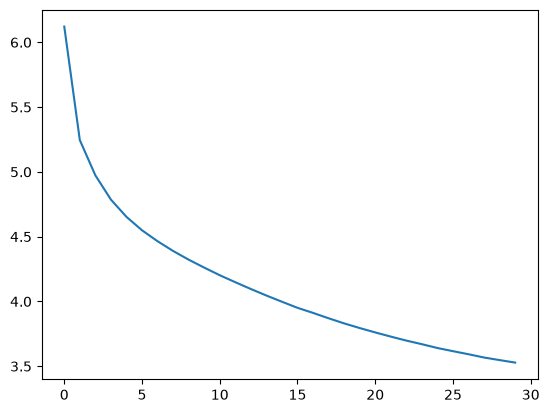

In [49]:
import matplotlib.pyplot as plt

plt.plot(costs)

In [31]:
def evaluate(X, y, params, batch_size=128):
    total_loss = 0.0
    total_correct = 0
    n = len(X)

    for start in range(0, n, batch_size):
        X_batch = X[start:start + batch_size]
        y_batch = y[start:start + batch_size]

        probs, _ = forward_propagation(X_batch, params)

        total_loss += compute_cost(y_batch, probs) * len(y_batch)
        total_correct += np.sum(
            np.argmax(probs, axis=1) == y_batch
        )

    return total_loss / n, total_correct / n

In [36]:
train_loss, train_accuracy = evaluate(
    X_train, y_train, params
)

val_loss, val_accuracy = evaluate(
    X_val, y_val, params
)

print(f"Train loss: {train_loss:.4f}")
print(f"Train accuracy: {train_accuracy:.4f}")
print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy:.4f}")



unk_idx = word_to_idx["<unk>"]

unknown_val = np.sum(y_val == unk_idx)
unknown_test = np.sum(y_test == unk_idx)

print(
    f"Unknown in validation targets: {unknown_val}/{len(y_val)} "
    f"({100 * unknown_val / len(y_val):.2f}%)"
)

print(
    f"Unknown in test targets: {unknown_test}/{len(y_test)} "
    f"({100 * unknown_test / len(y_test):.2f}%)"
)
known_mask = y_val != unk_idx

known_probs, _ = forward_propagation(
    X_val[known_mask], params
)

known_loss = compute_cost(
    y_val[known_mask], known_probs
)

known_accuracy = np.mean(
    np.argmax(known_probs, axis=1) == y_val[known_mask]
)

print(f"Known-word validation examples: {known_mask.sum()}")
print(f"Known-word validation loss: {known_loss:.4f}")
print(f"Known-word validation accuracy: {known_accuracy:.4f}")
from collections import Counter

# Most frequent target word in the training set
target_counts = Counter(y_train)
most_common_idx, most_common_count = target_counts.most_common(1)[0]

# Baseline always predicts the most frequent training target
baseline_train_accuracy = np.mean(y_train == most_common_idx)
baseline_val_accuracy = np.mean(y_val == most_common_idx)

print("Most frequent target:", idx_to_word[most_common_idx])
print(f"Baseline train accuracy: {baseline_train_accuracy:.4f}")
print(f"Baseline validation accuracy: {baseline_val_accuracy:.4f}")
val_probs, _ = forward_propagation(X_val, params)
val_predictions = np.argmax(val_probs, axis=1)

print("Most common validation predictions:")

for idx, count in Counter(val_predictions).most_common(15):
    print(f"{idx_to_word[idx]:15s} {count}")

from collections import Counter

token_counts = Counter(
    word
    for sentence in tokenized_sentences
    for word in sentence
)

for token, count in token_counts.most_common(30):
    print(repr(token), count)


print("Most common actual validation targets:")

for idx, count in Counter(y_val).most_common(15):
    print(f"{idx_to_word[idx]:15s} {count}")

train_accuracy = 0.3499
val_accuracy = 0.2223

print(
    f"Accuracy gap: "
    f"{(train_accuracy - val_accuracy) * 100:.2f} percentage points"
)

print("Training input mean:", X_train.mean())
print("Training input std:", X_train.std())
print("Validation input mean:", X_val.mean())
print("Validation input std:", X_val.std())

print(
    "Training zero rows:",
    np.sum(np.all(X_train == 0, axis=1))
)

print(
    "Validation zero rows:",
    np.sum(np.all(X_val == 0, axis=1))
)

for token in [".", ",", "'", "n't", "the", "i"]:
    if token in word_to_idx:
        idx = word_to_idx[token]

        train_count = np.sum(y_train == idx)
        val_count = np.sum(y_val == idx)

        print(
            f"{token!r}: "
            f"train={train_count}, "
            f"validation={val_count}"
        )

Train loss: 3.4389
Train accuracy: 0.2554
Validation loss: 6.3211
Validation accuracy: 0.1874
Unknown in validation targets: 199/5037 (3.95%)
Unknown in test targets: 190/4922 (3.86%)
Known-word validation examples: 4838
Known-word validation loss: 5.5367
Known-word validation accuracy: 0.1951
Most frequent target: .
Baseline train accuracy: 0.0802
Baseline validation accuracy: 0.0784
Most common validation predictions:
.               1435
i               358
the             324
to              307
was             262
,               207
'               201
a               152
n't             121
's              69
be              64
you             53
're             53
going           46
but             42
'.' 3956
"'" 2975
',' 1991
'i' 1836
'the' 1788
'to' 1348
'and' 1175
'a' 978
'you' 961
'it' 790
'was' 744
"n't" 652
'he' 637
'?' 606
"'s" 596
'me' 569
'my' 564
'of' 523
'that' 523
'in' 461
'but' 331
'do' 317
'with' 306
'on' 303
'at' 278
'she' 273
'his' 260
'for' 255
'what' 253
'did

In [51]:
A3_val, _ = forward_propagation(X_val, params)
val_pred = np.argmax(A3_val, axis=1)

print("Validation accuracy:", np.mean(val_pred == y_val) * 100)
print("Validation loss:", compute_cost(y_val, A3_val))
print()

A3_train, _ = forward_propagation(X_train, params)
train_pred = np.argmax(A3_train, axis=1)

print("train accuracy:", np.mean(train_pred == y_train) * 100)
print("train loss:", compute_cost(y_train, A3_train))
print()

A3_test, _ = forward_propagation(X_test, params)
test_pred = np.argmax(A3_test, axis=1)

print("test accuracy:", np.mean(test_pred == y_test) * 100)
print("test loss:", compute_cost(y_test, A3_test))

Validation accuracy: 18.741314274369664
Validation loss: 6.3210773

train accuracy: 25.54290053151101
train loss: 3.4389348

test accuracy: 19.280780170662332
test loss: 6.1954327


In [34]:
print("Output shape:", A3_train.shape)
print("Training labels shape:", y_train.shape)
print("Validation labels shape:", y_val.shape)

print("Training label range:",
      np.min(y_train), np.max(y_train))

print("Validation label range:",
      np.min(y_val), np.max(y_val))

print("Output min:", np.min(A3_train))
print("Output max:", np.max(A3_train))
print("Mean output row sum:", np.mean(np.sum(A3_train, axis=1)))

Output shape: (39510, 3579)
Training labels shape: (39510,)
Validation labels shape: (5037,)
Training label range: 0 3577
Validation label range: 0 3578
Output min: 0.0
Output max: 0.99898726
Mean output row sum: 1.0


In [52]:
def predict_next_word(context):
    context = context.lower().split()

    if not context:
        raise ValueError("Provide at least one context word.")

    # Check that all context words exist in the vocabulary
    unknown = [word for word in context if word not in word_to_idx]
    if unknown:
        raise ValueError(f"Unknown vocabulary words: {unknown}")

    x = context_to_vector(context, embedding_model).reshape(1, -1)
    probabilities, _ = forward_propagation(x, params)

    predicted_idx = int(np.argmax(probabilities[0]))
    return idx_to_word[predicted_idx]


# print(predict_next_word("sometimes"))
# print(predict_next_word("he was"))
# print(predict_next_word("it was a"))

In [80]:
def generate_text(start_text, num_words=50):
    words = start_text.lower().split()

    for _ in range(num_words):
        context = words[-3:]
        next_word = predict_next_word(" ".join(context))
        words.append(next_word)

    return " ".join(words)

print(generate_text("learning", 30))

learning , i 'll never complain . ' cause . ' cause . ' cause . ' cause . ' cause . ' cause . ' cause . ' cause .


In [ ]:
embedding_model.wv["baby"]

In [81]:
def show_top_predictions(context, top_n=5):
    words = context.lower().split()

    unknown = [w for w in words if w not in word_to_idx]
    if unknown:
        print("Unknown words:", unknown)
        return

    x = context_to_vector(words, embedding_model).reshape(1, -1)
    probabilities, _ = forward_propagation(x, params)

    top_indices = np.argsort(probabilities[0])[::-1][:top_n]

    print(f"\nContext: {context}")
    for idx in top_indices:
        print(
            f"{idx_to_word[idx]:<12} "
            f"{probabilities[0][idx]:.4f}"
        )

show_top_predictions("the")
show_top_predictions("he was")
show_top_predictions("it was a")
show_top_predictions("once upon a time")


Context: the
portuguese   0.0532
other        0.0244
street       0.0227
only         0.0214
metal        0.0194

Context: he was
n't          0.0537
squatting    0.0455
a            0.0412
flattered    0.0395
punishing    0.0391

Context: it was a
bit          0.0760
little       0.0755
mystery      0.0753
nightmare    0.0587
dandy        0.0436
Unknown words: ['upon']
